# 04-数字孪生、仿真与Sim-to-Real


## 1. 本篇范围

前两篇已经介绍机械臂的电机、传动和位置反馈。这些部件组成了真实机械臂，但开发运动算法、反复调试抓取动作时，直接使用实体设备会遇到损坏风险、硬件磨损和实验效率问题。

本篇依据 `具身智能实战02.pptx` 第 **1—38 页**整理。课件先介绍 Git、Conda 和 Node.js，建立开发环境的基础，再讨论数字孪生、仿真驱动开发、机器人学习的数据来源，以及从仿真迁移到现实的挑战。

课件这一部分的主线是：**先在虚拟环境中验证和训练，再通过真实设备校准模型、验证效果。** 第 38 页引出 URDF，具体模型结构和标签留到第 05 篇。

本篇只整理 PPT 已讲到的内容。课件在这些页中没有提供具体仿真平台的安装命令、启动步骤或机械臂项目代码，因此这里先讲清原理与开发思路。


## 2. Git：管理代码历史与协作

课件第 1 页用一张图说明 Git 的几个主要区域，以及代码从编辑到提交、同步的过程。

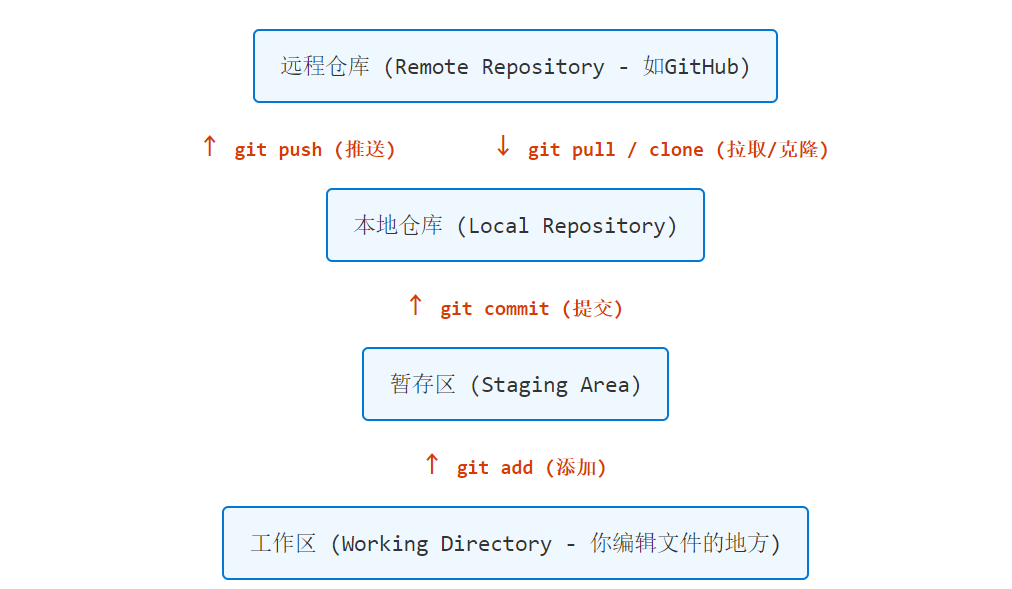

| 区域 | 保存什么 | 相关操作 |
|---|---|---|
| 工作区（Working Directory） | 当前正在编辑的项目文件 | 修改代码、模型或配置 |
| 暂存区（Staging Area） | 准备纳入下一次提交的改动 | `git add` |
| 本地仓库（Local Repository） | 本机保存的提交历史 | `git commit` |
| 远程仓库（Remote Repository） | 远程保存的项目与提交历史，例如 GitHub 上的仓库 | `git push`、`git pull`、`git clone` |

按照图中的顺序，编辑完成后先用 `git add` 暂存改动，再用 `git commit` 形成一次本地提交。需要同步到远程仓库时，使用 `git push`。

> **补充说明：**`git clone` 用于首次取得项目，通常会创建本地仓库并检出工作区文件。`git pull` 用于已有仓库，获取远程更新后整合到当前分支。两者在课件图中共用一个向下箭头，但适用阶段不同。一次本地提交也不会自动上传到远程。

机械臂项目中的控制代码、模型文件和配置发生变化时，Git 可以记录这些变化，方便回看某个实验使用的版本。


## 3. 依赖冲突与环境隔离

### 3.1 什么是“依赖地狱”

课件用两个项目说明问题：不同项目可能需要同一个软件包的不同版本。

| 项目 | `pandas` 版本 | `numpy` 版本 |
|---|---|---|
| 项目 A：数据分析 | 1.5 | 1.21 |
| 项目 B：机器学习 | 2.1 | 1.24 |

如果两个项目共用一套全局环境，更新软件包以满足项目 B，可能使项目 A 的代码无法运行。反过来，保留旧版本又可能无法满足项目 B。

这组版本来自课件，用于说明依赖冲突，不是机械臂项目的安装清单。

### 3.2 Conda 的解决方法

Conda 同时提供包管理和环境管理能力。它为不同项目建立独立环境，每个环境可以有自己的 Python 版本和软件包版本。

例如，项目 A 使用 Python 3.8，项目 B 使用 Python 3.10。进入哪个环境，就使用哪个环境中的解释器与依赖。安装在 A 环境中的包不会直接改变 B 环境。

课件还指出，Conda 不只管理 Python，也能管理 R、C++ 等相关依赖。

> **补充说明：**环境隔离主要解决依赖互相干扰的问题。要让他人复现实验，还需要记录实际使用的代码版本和依赖版本。仅仅创建一个环境名称，无法说明里面具体安装了什么。


## 4. Miniconda 安装与环境工作流

### 4.1 课件的安装选择

课件推荐 Miniconda。它只包含 Conda、Python 和必要组件，初始安装较轻量。Anaconda 通常预装更多科学计算工具，体积也更大。

课件把 Miniconda 的大小写为“约 100 MB”，这是课程中的近似描述，实际安装包大小随版本和平台变化。

课件给出的下载入口是 [Miniconda 官方文档](https://docs.conda.io/en/latest/miniconda.html)。安装后，在新打开的终端中验证：

```powershell
conda --version
```

能看到 Conda 的版本号，说明当前终端可以找到该命令。

> **课件说明与使用边界：**PPT 为方便初学者，建议 Windows 安装时勾选加入 `PATH`。这会改变终端寻找 Python 和相关程序的方式。使用安装器提供的 Anaconda Prompt / Miniconda Prompt 也可以运行 Conda；若电脑已有其他 Python 环境，需要留意解释器是否发生切换。

### 4.2 一个项目的标准流程

课件把工作过程分成创建、激活、安装依赖、开发和退出环境几个阶段。

| 操作 | 课程命令 | 含义 |
|---|---|---|
| 创建环境 | `conda create -n <env_name> python=x.x` | 指定环境名称与 Python 版本 |
| 激活环境 | `conda activate <env_name>` | 切换到项目使用的环境 |
| 安装依赖 | `conda install <package_name>` | 在当前环境中安装软件包 |
| 卸载依赖 | `conda uninstall <package_name>` | 从当前环境移除软件包 |
| 查看环境 | `conda env list` 或 `conda info --envs` | 查看已有环境及当前环境 |
| 退出环境 | `conda deactivate` | 退出当前激活的环境 |
| 删除环境 | `conda env remove -n <env_name>` | 移除指定环境及其中的依赖 |

`<env_name>`、`<package_name>` 和 `x.x` 都是需要替换的占位符。Python 版本应按实际项目要求选择。

操作顺序中的关键是**先激活项目环境，再安装该项目的依赖**。在错误环境中安装，即使命令成功，也不能保证运行项目时能找到对应的软件包。

退出环境和删除环境不同：`conda deactivate` 保留环境，后续可以继续激活；`conda env remove` 会移除环境。


## 5. Git 与 Conda 各自负责什么

课件把 Git 与 Conda 称为标准化开发环境的“黄金搭档”。

| 工具 | 主要管理对象 | 课件中的关键词 |
|---|---|---|
| Git | 代码变化的历史，以及不同开发者之间的协作 | `clone`、`commit`、`push`、`pull` |
| Conda | 项目所需的运行环境与软件依赖 | `create`、`activate`、`install`、`deactivate` |

Git 帮助回答“这次实验用了哪个版本的代码”，Conda 帮助回答“这份代码运行在哪套 Python 与依赖中”。两部分配合，实验结果才更容易追溯。

例如，同一段机械臂代码在不同依赖版本中出现不同表现时，只知道提交编号还不够，也需要检查运行环境。


## 6. Node.js：运行 JavaScript 工具与项目

### 6.1 为什么课程介绍 Node.js

课件列出 Node.js 的几类用途：

- 开发 Web 服务器和 API 接口。
- 运行 React、Vue 等前端项目的构建工具。
- 编写或运行命令行工具。
- 使用 npm 管理的开源软件包。

Node.js 提供 JavaScript 运行环境，npm 是随常见 Node.js 安装包提供的包管理工具。本节只说明它们的用途与安装验证，PPT 尚未给出机械臂网页项目的具体启动命令。

### 6.2 安装与验证

1. 访问 [Node.js 官网](https://nodejs.org)，选择对应操作系统的安装包。
2. 课程推荐 **LTS（长期支持）版本**，用于更稳定的开发环境。Current 分支优先提供新功能。
3. 运行安装程序，按默认选项完成安装。常见安装器会将 `node`、`npm` 加入 `PATH`。
4. 新开一个终端，分别检查两个命令：

```powershell
node -v
npm -v
```

两条命令都返回版本号，说明当前终端可以调用 Node.js 与 npm。这里不写固定版本号，应以安装后的实际输出为准。

> **补充说明：**PPT 写成 `$node -v` 和 `$npm -v`。其中 `$` 按命令提示符理解，不属于要输入的命令。Windows PowerShell 中直接输入上面的命令即可。


## 7. 真实机械臂开发的成本与风险

完成环境准备后，课件提出：是否应该立刻在真实机械臂上编写、运行和调试所有代码？

直接开发主要有两类困难。

**第一类是物理损坏。**运动学算法中的错误，可能让机械臂撞到自身、桌面或周围物体。程序中的一次错误动作，会转化成真实的机械碰撞。

**第二类是时间与硬件损耗。**抓取算法可能需要大量重复实验。实体设备每次都要完成运动、复位和准备，实验受场地与设备数量限制，反复动作还会带来磨损。

因此，课件引入**仿真驱动的开发模式**：先在虚拟环境中完成大量开发、测试和优化，再进入实体设备验证。

这种方式让开发者可以先检查动作逻辑与模型行为，也便于反复重现同一条件下的实验。


## 8. 仿真与数字孪生

### 8.1 课件中的概念比较

仿真（Simulation）通过模型模拟对象或过程。数字孪生（Digital Twin）在数字空间中建立物理实体的动态虚拟副本，并与实体状态联系起来。

| 比较项 | 课件中的传统仿真 | 课件中的数字孪生 |
|---|---|---|
| 焦点 | 某个特定过程 | 完整物理实体 |
| 范围 | 局部、离线 | 全局、实时同步 |
| 目的 | 分析与验证 | 预测、监控、闭环交互 |
| 示例 | 齿轮受力分析、电路性能模拟 | 与真实机械臂状态联系的虚拟机械臂 |

课件强调，数字孪生不只需要相似外观，还需要表达与任务有关的物理属性，并能接收传感器数据、响应控制指令。

| 内容 | 对机械臂的含义 |
|---|---|
| Geometry：几何 | 连杆外形、长度及部件之间的位置关系 |
| Physics：物理 | 质量、惯性、摩擦及其他影响运动的属性 |
| Sensing：感知 | 接收真实关节位置等传感器数据 |
| Actuation：执行 | 响应关节或运动控制指令 |

> **补充说明：**上表是课件为了入门采用的比较，仿真本身也可以覆盖完整系统或实时运行。一个离线三维模型可以成为数字孪生的起点；如果尚未接入实体数据、完成模型校准，就还没有形成课件所说的实时同步与闭环交互。

### 8.2 课件列举的应用

- **航空发动机：**课件以 GE 航空为例，说明如何用发动机的数字孪生监控状态、预测故障并安排维护。
- **城市交通：**建立交通系统模型，模拟车流、调整信号配时和规划应急路线。
- **航天机器人：**课件以 NASA 火星车为例，说明如何在地球上的虚拟环境中测试行驶路径与操作指令。

这些是课件用于说明应用方向的案例，本篇没有展开具体系统实现。

### 8.3 本课程的任务

为实体机械臂建立对应的虚拟模型，使它成为开发、测试和实验的平台。接下来需要描述机械臂的结构，并逐步让模型中的运动与真实设备相符。


## 9. 仿真降低开发成本

课件分别讨论硬件成本、时间成本和迭代成本。

| 成本 | 实体实验的限制 | 仿真的作用 |
|---|---|---|
| 硬件成本 | 碰撞、超限动作可能损坏设备 | 在虚拟模型上测试失败动作，减少实体损坏 |
| 时间成本 | 设备数量、场地和实验准备限制重复次数 | 在资源允许时并行运行多个实验 |
| 迭代成本 | 修改样机尺寸或部件往往需要制造和装配 | 先调整模型参数，快速比较不同设计 |

例如，改变连杆长度或电机扭矩后，可以先在模型中观察动作范围与运动表现，再决定是否修改真实样机。课件把这种方式称为快速设计迭代（Rapid Prototyping）。

> **补充说明：**课件用“虚拟机器人撞坏的成本为零”突出没有实体硬件损失。仿真仍然需要建模、计算资源和维护时间。并行实验的数量也受计算能力与仿真复杂度限制。


## 10. 仿真中的安全验证与极端工况

课件从设备安全、人员安全和极端情况测试三个方面展开。

**设备安全：**在虚拟环境中发现错误动作，可以减少实体机械臂因算法错误发生碰撞或受损的机会。

**人员安全：**在人机协作场景中，先验证交互算法的运动范围和动作行为，再安排真实实验。

**极端情况：**失重环境、力矩接近上限等工况，在现实中可能难以重现或成本较高。模型允许开发者在设定条件下重复检查系统的表现。

> **课件表述的边界：**PPT 使用“确保绝对开发安全”等强调性措辞。仿真能降低直接试错的物理风险，但其验证结果受模型准确性和测试覆盖范围限制。仿真通过之后，真实机械臂仍需要进行相应的实机验证。


## 11. 仿真提升开发与排错效率

### 11.1 软硬件开发并行

算法工程师可以在模型中开发和调试，无需等到实体样机制造完成。模型准备好后，运动算法和硬件制作能够并行推进。

课件这一页的标题写为“前端开发与后端解耦”，正文具体讨论的是**算法开发与实体硬件准备的解耦**。

### 11.2 在可控条件下定位问题

真实机械臂的动作失败可能来自不同因素：

- 算法逻辑错误。
- 传感器噪声。
- 机械结构误差。
- 环境干扰。

如果这些因素同时存在，很难判断根因。仿真允许先使用较理想的条件，观察算法能否完成预期动作，再逐步研究其他因素的影响。

> **补充说明：**理想仿真中通过的动作，只能说明它在当前模型和条件下成立。为了评估现实表现，还需要加入与真实设备有关的噪声、误差或延迟。

### 11.3 自动化测试与回归测试

课件指出，可以编写脚本让虚拟机器人自动执行大量测试。代码更新后，再运行相同测试，检查既有功能是否受到影响，这就是回归测试（Regression Testing）。

可重复的模型与初始条件让前后版本更容易比较，也减少了每次都人工摆放设备、准备实验的工作。


## 12. 机器人学习的交互数据

课件接着把仿真与机器人 AI 联系起来。图像识别通常依赖大量图片，而机器人学习还涉及动作与环境之间的交互。

PPT 用下面三个量描述机器人学习的数据：

| 数据 | 含义 | 抓取任务中的理解示例 |
|---|---|---|
| State：状态 | 当前机器人与环境的情况 | 关节位置、物体位置等 |
| Action：动作 | 智能体选择的控制行为 | 改变关节目标、执行抓取等 |
| Reward：奖励 | 环境对行为结果的评价 | 是否成功抓取等 |

表中的抓取例子只是解释这些术语，没有指定本课程后续算法的实际数据字段或奖励公式。

在实体设备上收集大量交互，需要不断执行动作、等待结果、复位并准备下一次实验。采集速度受机械运动速度限制，同时还要考虑硬件磨损。

课件用“数百万次交互”“抓取一百万次可能需要数年”说明规模化采集的困难。

> **补充说明：**这些数量用于强调数据需求，具体规模和耗时取决于任务、算法、并行设备数量及单次实验时长。`State, Action, Reward` 主要体现强化学习的交互思路，不表示所有机器人学习方法都必须采集奖励。


## 13. 仿真作为机器人 AI 的训练场

### 13.1 更容易生成和重复交互数据

仿真中可以快速重置环境、改变初始条件，并在计算资源允许时并行运行多个实验。机器人试错不再只依赖某一台实体设备，因此可以降低数据采集的时间与硬件成本。

课件把它称为“近乎无限、廉价、高速的数据来源”。这里的“无限”表达持续生成数据的能力，实际规模仍受算力、时间和模型质量限制。

### 13.2 强化学习中的试错

强化学习（Reinforcement Learning，RL）的智能体通过行动与环境交互，依据结果调整行为。虚拟环境允许它进行大量试错，失败后重新开始。

课件用“数亿次试错、几个小时”突出仿真的加速潜力。这是对能力的示意，不能作为任何仿真任务都能达到的性能保证。

本篇先理解仿真为何适合训练。强化学习算法与具体训练过程留到后面的课程笔记。

### 13.3 模仿学习与数据增强

对于模仿学习等方法，课件指出可以使用仿真生成更多样的数据。随机改变光照、纹理、物体位置或物理参数，让训练数据覆盖更多情况。

这种做法称为**领域随机化（Domain Randomization）**，目的是减少模型只适应某一种固定环境的情况，提高它应对环境变化的能力。

> **补充说明：**数据数量与标签质量需要一起考虑。模仿学习仍需要可学习的示范或目标行为，仅生成大量随机失败动作，并不能自动形成有效示范数据。


## 14. Sim-to-Real 与现实鸿沟

Sim-to-Real 指把在仿真中开发或训练的算法、策略迁移到真实系统。

困难在于：**仿真模型无法完全复制现实。**课件把两者的差异称为现实鸿沟（Reality Gap）。一个在虚拟机械臂上表现良好的策略，换到真实机械臂上可能失效。

结合课件提到的参数和环境变化，可以从下面几个方面理解差异：

| 差异来源 | 与本课内容的联系 |
|---|---|
| 物理参数 | 质量、摩擦与模型设定不同，运动结果就可能改变 |
| 时间特性 | 真实系统存在延迟，指令与反馈的时序可能不同 |
| 视觉环境 | 光照、纹理和物体位置变化，影响视觉输入 |
| 机械与传感误差 | 实体设备中的误差、噪声会影响动作与状态反馈 |

因此，虚拟环境中的成功还需要通过真实设备确认。后续改善应围绕具体差异进行，而不是只增加理想环境中的训练次数。


## 15. 缩小现实鸿沟的三种方法

课件依次介绍领域随机化、系统辨识和真实环境微调。

### 15.1 领域随机化

训练时随机改变环境或模型参数，例如光照、纹理、物体位置和物理参数。模型经历多种条件后，更有机会应对真实环境的不确定性。

> **补充说明：**随机化的范围应围绕实际可能出现的变化。加入很多与任务无关的变化，并不必然提高真实设备上的效果。

### 15.2 系统辨识

系统辨识（System Identification）通过测量真实机器人，估计它的物理参数，再用这些结果校准仿真模型。

课件列举的参数包括质量、摩擦力和延迟。例如，真实关节响应比模型更慢，就需要检查并调整模型中的相关参数。

其作用是让虚拟机械臂更接近真实机械臂，减少策略在两个系统中面对的差异。

### 15.3 真实环境微调

微调（Fine-tuning）把已经在仿真中预训练的模型放到真实机器人上，再用少量真实数据继续训练，使模型适应实际环境。

这里的“少量”是相对于主要训练阶段而言，实际仍要根据任务效果决定需要多少数据。

| 方法 | 主要作用 |
|---|---|
| 领域随机化 | 让模型适应一定范围内的变化 |
| 系统辨识 | 校准仿真参数，使模型贴近实机 |
| 真实环境微调 | 使用真实数据进一步调整模型 |

这三种方法可以配合使用，但每一种都需要通过实际结果判断是否有效。


## 16. 课程的开发思路与 URDF 入口

课件第 36 页提出“在仿真中大规模训练，在现实中少量微调”，并使用 **99% / 1%** 的图示强调训练与实机适配的侧重点。

> **课件表述的边界：**这些比例是教学示意，PPT 没有给出对应的实验统计。实际工作量和数据比例随任务而变，不能据此规定真实设备只需承担 1% 的验证。

第 37 页回到本节结论：数字孪生与仿真提供可控的研发环境，既支持开发测试，也支持 AI 所需的数据生成和训练。与此同时，现实鸿沟决定了真实设备的校准和验证仍然必要。

接下来需要回答的是：怎样向计算机描述机械臂的身体结构？

课件第 38 页引出 **URDF（Unified Robot Description Format，统一机器人描述格式）**，把它比作机器人的“建筑蓝图”。下一篇将继续整理这种描述格式中的连杆、关节及其属性。


## 17. 来源与覆盖范围

资料来自[用户提供的课程网盘](https://pan.baidu.com/s/1JTzTYgpIAiSUroQ2-ihJHA?pwd=1234)，提取码为 `1234`。资料目录为“6、嵌入式具身智能机械臂／视频资料／课程ppt”。

本篇主资料为 `具身智能实战02.pptx`，按其实际页序整理：

| 笔记内容 | 对应 PPT 页码 |
|---|---|
| Git 核心操作及原图 | 1 |
| 依赖冲突、Conda 安装与环境流程 | 2—6 |
| Git 与 Conda 的分工 | 7 |
| Node.js 用途、安装与验证 | 8—11 |
| 真实机械臂开发的问题与仿真驱动开发 | 12—15 |
| 数字孪生定义、应用与课程任务 | 16—19 |
| 仿真的成本、安全与效率价值 | 20—27 |
| 机器人学习的数据需求与仿真训练 | 28—33 |
| Sim-to-Real、现实鸿沟及改善方法 | 34—36 |
| 本节结论与 URDF 引入 | 37—38 |

Git 操作图作为 Notebook 附件直接嵌入，移动笔记文件后仍可显示。第 38 页的电脑与机器人图标只用于过渡，没有额外的模型结构信息，保留其文字内容即可。

本篇未转录配套视频。标为“补充说明”或“课件表述的边界”的段落用于解释当前概念、命令或结论的适用条件。
